## 1 · Imports

In [3]:
import math
import time

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import torch
import torch.nn as nn
from sklearn.datasets import make_moons
from tqdm.auto import tqdm

from torchcfm.conditional_flow_matching import (
    ExactOptimalTransportConditionalFlowMatcher,
    ConditionalFlowMatcher,
)

import sys
sys.path.insert(0, "/home/shervink/flow_matching/flow-maps/py")

import numpy as np
import matplotlib.pyplot as plt
from common.datasets import sample_two_moons

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is required for this notebook — no GPU detected.")

import importlib
import sampling_utils
from sampling_utils import euler_sample, sample_two_moons

import sys, os
sys.path.insert(0, "/home/shervink/flow_matching/flow-maps/py")

import numpy as np
import torch
import torch.nn as nn
from flax.serialization import msgpack_restore
from common.datasets import sample_two_moons

import importlib
import sampling_utils
importlib.reload(sampling_utils)
from sampling_utils import sample_rho0, flow_map_sample, make_target



device = torch.device("cuda")

torch.manual_seed(42)
torch.cuda.manual_seed_all(42)
np.random.seed(42)

print(f"device: {device}  ({torch.cuda.get_device_name(device)})")

device: cuda  (NVIDIA RTX A5000)


## 2 . Loading JAX Flow Map model and converting to Pytorch

In [4]:
"""
Load the JAX/Flax two-moons flow-map checkpoint and convert it to a
matching PyTorch model.

Architecture (from configs/two_moons.py + network_utils.py):
  FlowMapMLP
  - Input : [s, t, x/rescale]  →  dim 4  (2 time scalars + 2-D point)
  - phi_mlp (MLP):
      Linear(4  → 256) + GELU
      Linear(256 → 256) + GELU  (× n_hidden = 3)
      Linear(256 → 2)
  - phi = rescale * mlp(inp)
  - X(s,t,x) = x + (t-s) * phi

Key conversion detail:
  Flax Dense kernel shape : [in, out]
  PyTorch Linear weight   : [out, in]  → must transpose
"""



# ── paths ────────────────────────────────────────────────────────────────────
CKPT = "/home/shervink/flow_matching/flow-maps/py/checkpoints/two_moons_paper_lsd_15.pkl"
# CKPT = "/home/shervink/flow_matching/checkpoints/initial_tests/two_moons_ot_cfm/step_004500.pkl"

# Must match training: adaptive gaussian_scale sets network.rescale = std(target)
RESCALE = float(np.std(sample_two_moons(500_000)))
print(f"RESCALE (from training data std): {RESCALE:.4f}")

# ── 1. load raw parameter dict ────────────────────────────────────────────────
with open(CKPT, "rb") as f:
    raw = msgpack_restore(f.read())

# The EMATrainState serialises as:
#   raw["params"]      → TrainState.params  (the variable collection)
#   raw["ema_params"]  → dict keyed by EMA factor
#
# Use the EMA-smoothed weights (0.999) for inference.
ema_key = list(raw["ema_params"].keys())[0]
print(f"EMA keys available: {list(raw['ema_params'].keys())}")
print(f"Using EMA key: {ema_key!r}   step={int(raw['step'])}")

phi = raw["ema_params"][ema_key]["params"]["flow_map"]["phi_mlp"]
print("phi_mlp Dense layers found:", sorted(phi.keys()))
for k in sorted(phi.keys()):
    print(f"  {k}: kernel {phi[k]['kernel'].shape}  bias {phi[k]['bias'].shape}")

# ── 2. define matching PyTorch model ─────────────────────────────────────────
class FlowMapMLP(nn.Module):
    """
    Replicates FlowMapMLP from network_utils.py.
    forward(s, t, x) returns X(s,t,x) = x + (t-s) * phi(s,t,x).
    s, t : scalars or (N,) tensors
    x    : (N, 2) tensor
    """
    def __init__(self, n_hidden=3, n_neurons=256, input_dim=4, output_dim=2,
                 rescale=0.5):
        super().__init__()
        self.rescale = rescale
        layers = []
        in_dim = input_dim
        # first layer
        layers += [nn.Linear(in_dim, n_neurons), nn.GELU()]
        # n_hidden hidden layers
        for _ in range(n_hidden):
            layers += [nn.Linear(n_neurons, n_neurons), nn.GELU()]
        # output layer
        layers += [nn.Linear(n_neurons, output_dim)]
        self.phi_mlp = nn.Sequential(*layers)

    def calc_b(self, t, x):
        """Induced velocity on the diagonal: b(t, x) = phi(t, t, x)."""
        if t.dim() == 0:
            t = t.expand(x.shape[0])
        st = torch.stack([t, t], dim=-1)
        inp = torch.cat([st, x / self.rescale], dim=-1)
        return self.rescale * self.phi_mlp(inp)

    def forward(self, s, t, x):
        # x : (N, 2);  s, t : () or (N,)
        if s.dim() == 0:
            s = s.expand(x.shape[0])
            t = t.expand(x.shape[0])
        st = torch.stack([s, t], dim=-1)          # (N, 2)
        inp = torch.cat([st, x / self.rescale], dim=-1)   # (N, 4)
        phi = self.rescale * self.phi_mlp(inp)     # (N, 2)
        return x + (t - s).unsqueeze(-1) * phi     # X(s,t,x)


# ── 3. copy Flax weights → PyTorch ───────────────────────────────────────────
def flax_to_pt(flax_dense, pt_linear):
    """Copy a single Flax Dense layer into a PyTorch Linear layer."""
    W = torch.from_numpy(np.array(flax_dense["kernel"]))   # [in, out]
    b = torch.from_numpy(np.array(flax_dense["bias"]))     # [out]
    pt_linear.weight.data.copy_(W.T)   # PyTorch wants [out, in]
    pt_linear.bias.data.copy_(b)

model = FlowMapMLP(n_hidden=3, n_neurons=256, input_dim=4, output_dim=2,
                   rescale=RESCALE).to(device)

# phi_mlp Sequential layout:
#   [0] Linear  [1] GELU  [2] Linear  [3] GELU  ... [2k] Linear  [2k+1] GELU  [last] Linear
# Dense_0 → layer 0, Dense_1 → layer 2, Dense_2 → layer 4, ..., Dense_4 → layer 8
dense_to_seq = {
    "Dense_0": 0,
    "Dense_1": 2,
    "Dense_2": 4,
    "Dense_3": 6,
    "Dense_4": 8,
}
for dense_name, seq_idx in dense_to_seq.items():
    flax_to_pt(phi[dense_name], model.phi_mlp[seq_idx])

print("\nWeights copied successfully.")

# ── 4. quick sanity check ─────────────────────────────────────────────────────
model.eval()
with torch.no_grad():
    x_test = torch.randn(5, 2, device=device)
    s_test = torch.zeros(5, device=device)
    t_test = torch.ones(5, device=device)
    out = model(s_test, t_test, x_test)
    print(f"Test output shape: {out.shape}  (expected (5, 2))")
    print(f"Sample output:\n{out.cpu().numpy().round(4)}")




RESCALE (from training data std): 0.7501
EMA keys available: ['0.999']
Using EMA key: '0.999'   step=15000
phi_mlp Dense layers found: ['Dense_0', 'Dense_1', 'Dense_2', 'Dense_3', 'Dense_4']
  Dense_0: kernel (4, 256)  bias (256,)
  Dense_1: kernel (256, 256)  bias (256,)
  Dense_2: kernel (256, 256)  bias (256,)
  Dense_3: kernel (256, 256)  bias (256,)
  Dense_4: kernel (256, 2)  bias (2,)

Weights copied successfully.
Test output shape: torch.Size([5, 2])  (expected (5, 2))
Sample output:
[[-0.3266  1.2718]
 [-0.4168  1.1091]
 [-1.2023  0.5473]
 [-0.1974 -0.7245]
 [ 0.637  -1.1458]]


## 3 . Sampling Test

RESCALE used: 0.7501
target std: 0.7503   base std: 0.7534
 1-step generated std: 0.7473
 5-step generated std: 0.7461
10-step generated std: 0.7482
25-step generated std: 0.7484


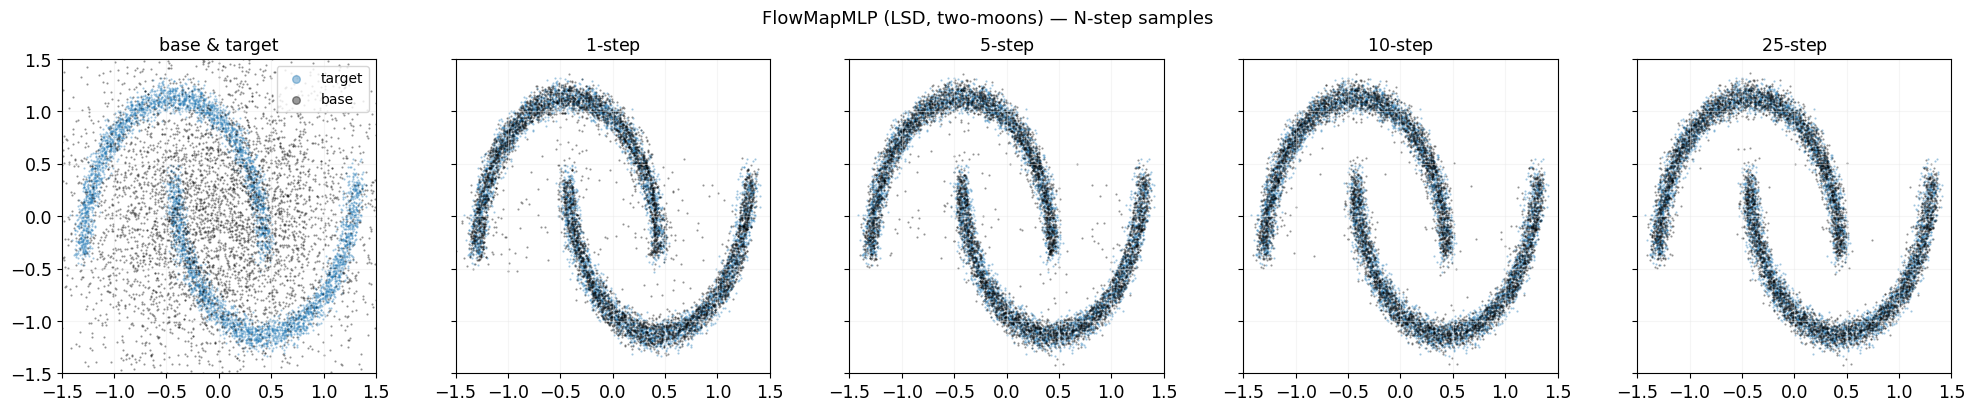

In [5]:
"""
Visualise flow-map samples at 1, 5, 10, 25 NFE (+ base/target panel).
Mirrors make_lowd_plot() in common/logging.py.

Generated points are NOT post-normalized — they are raw flow-map outputs.
Any mismatch with the target is usually from (1) wrong RESCALE at inference,
or (2) plotting target data with a different sampler/normalization than training.
"""


# ── data ──────────────────────────────────────────────────────────────────────
N_PLOT  = 5_000
steps   = [1, 5, 10, 25]

x1s  = make_target(N_PLOT)                                    # target (numpy)
x0s  = sample_rho0(N_PLOT, rescale=RESCALE, device=device)    # noise  (torch, GPU)

print(f"RESCALE used: {RESCALE:.4f}")
print(f"target std: {x1s.std():.4f}   base std: {x0s.std().item():.4f}")

xhats = {}
model.eval()
for N in steps:
    xhats[N] = flow_map_sample(model, x0s, N).cpu().numpy()
    print(f"{N:2d}-step generated std: {xhats[N].std():.4f}")

x0s_np = x0s.cpu().numpy()

# ── plot ──────────────────────────────────────────────────────────────────────
titles = ["base & target"] + [f"${N}$-step" for N in steps]
ncols  = len(titles)
fw, fh = 4, 4
fontsize = 12.5

fig, axs = plt.subplots(1, ncols, figsize=(fw * ncols, fh),
                        sharex=True, sharey=True, constrained_layout=True)

for ax in axs:
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_aspect("equal")
    ax.grid(color="0.90", alpha=0.4)
    ax.tick_params(labelsize=fontsize)

for jj, (ax, title) in enumerate(zip(axs, titles)):
    ax.set_title(title, fontsize=fontsize)
    ax.scatter(x1s[:, 0], x1s[:, 1], s=0.3, alpha=0.4, c="C0", label="target")
    if jj == 0:
        ax.scatter(x0s_np[:, 0], x0s_np[:, 1], s=0.3, alpha=0.4,
                   c="black", label="base")
    else:
        N = steps[jj - 1]
        ax.scatter(xhats[N][:, 0], xhats[N][:, 1], s=0.3, alpha=0.4,
                   c="black", label="generated")

axs[0].legend(markerscale=10, fontsize=10, loc="upper right")
plt.suptitle("FlowMapMLP (LSD, two-moons) — N-step samples", fontsize=13)
plt.show()

## 4 . Sampling Test with induced vector field (X(t,t))

Generated samples: torch.Size([2000, 2])  |  Trajectory: torch.Size([101, 2000, 2])
sample std: 0.7430  (target/rescale ~ 0.7501)


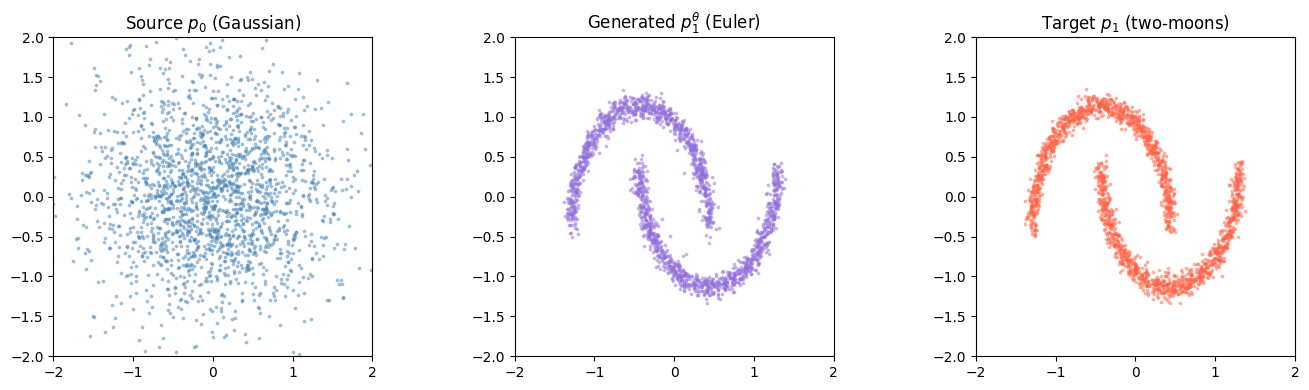

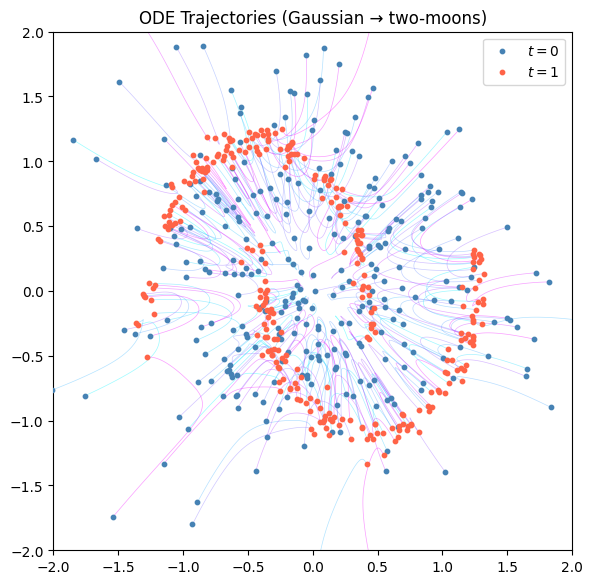

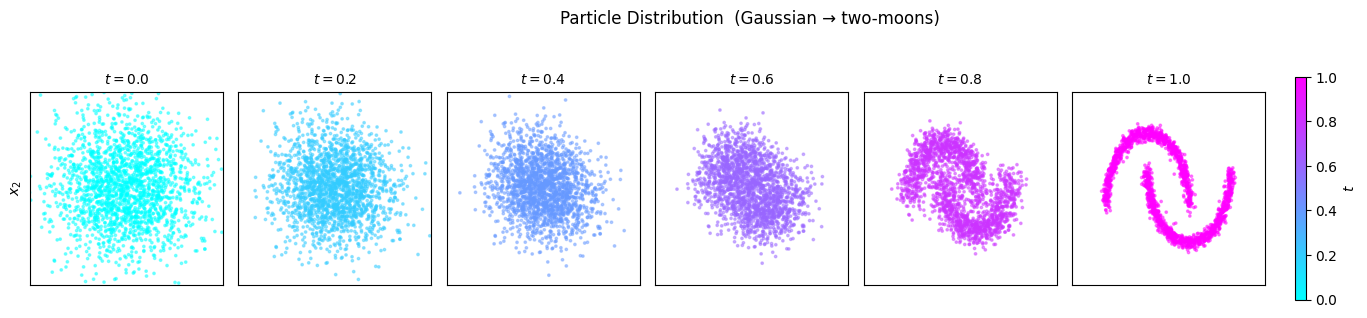

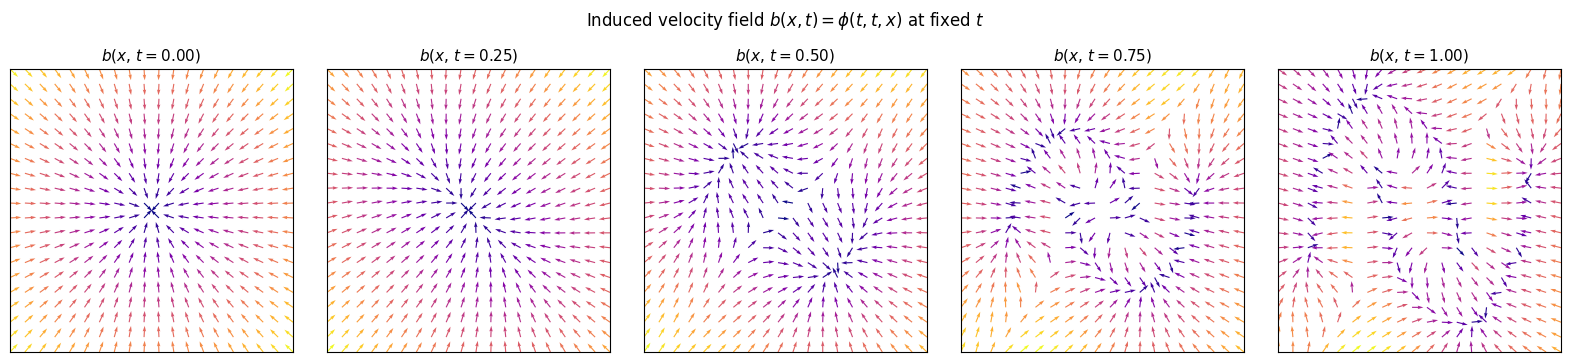

In [6]:



samples, trajectory = euler_sample(model, n=2000, n_steps=100, return_traj=True)
print(f"Generated samples: {samples.shape}  |  Trajectory: {trajectory.shape}")
print(f"sample std: {samples.std():.4f}  (target/rescale ~ {RESCALE:.4f})")

# ── Generated samples vs target ───────────────────────────────────────────────
n_vis = 2000
x0_vis = trajectory[0].numpy()          # source noise from this euler run
x1_ref = sample_two_moons(n_vis)        # training target distribution

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].scatter(x0_vis[:, 0], x0_vis[:, 1], s=3, alpha=0.4, c="steelblue")
axes[0].set_title("Source $p_0$ (Gaussian)")

axes[1].scatter(samples[:, 0], samples[:, 1], s=3, alpha=0.4, c="mediumpurple")
axes[1].set_title("Generated $p_1^{\\theta}$ (Euler)")

axes[2].scatter(x1_ref[:, 0], x1_ref[:, 1], s=3, alpha=0.4, c="tomato")
axes[2].set_title("Target $p_1$ (two-moons)")

lim = 2.0
for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)

plt.tight_layout()
plt.show()

# ── Trajectory plot: show a subset of particles moving from 0→1 ───────────────
TARGET_NAME = "two-moons"
n_show = 300
idx = np.random.choice(2000, n_show, replace=False)
traj_sub = trajectory[:, idx, :].numpy()   # (T, n_show, 2)
T = traj_sub.shape[0]

fig, ax = plt.subplots(figsize=(6, 6))
cmap = plt.get_cmap("cool")

for i in range(n_show):
    color = cmap(i / n_show)
    ax.plot(traj_sub[:, i, 0], traj_sub[:, i, 1],
            lw=0.5, alpha=0.4, color=color)

# start & end points
ax.scatter(*traj_sub[0].T, s=10, c="steelblue", zorder=5, label="$t=0$")
ax.scatter(*traj_sub[-1].T, s=10, c="tomato", zorder=5, label="$t=1$")
ax.set_aspect("equal")
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_title(f"ODE Trajectories (Gaussian → {TARGET_NAME})")
ax.legend()
plt.tight_layout()
plt.show()

# ── Snapshot plots: distribution at fixed time steps ──────────────────────────
# Uses the full trajectory tensor (T+1, n, 2) from euler_sample above.
SNAP_TIMES = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

T_steps = trajectory.shape[0] - 1          # number of Euler steps (= n_steps)
snap_indices = [round(t * T_steps) for t in SNAP_TIMES]

ncols = len(SNAP_TIMES)
fig, axes = plt.subplots(1, ncols, figsize=(3.2 * ncols, 3.4),
                         gridspec_kw={"wspace": 0.08})

for ax, step_idx, t_val in zip(axes, snap_indices, SNAP_TIMES):
    pts = trajectory[step_idx].numpy()      # (n, 2)
    ax.scatter(pts[:, 0], pts[:, 1], s=3, alpha=0.45,
               c=[t_val] * len(pts), cmap="cool", vmin=0, vmax=1)
    ax.set_title(f"$t = {t_val:.1f}$", fontsize=10)
    ax.set_aspect("equal")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_xticks([]); ax.set_yticks([])

axes[0].set_ylabel("$x_2$")
fig.suptitle(f"Particle Distribution  (Gaussian → {TARGET_NAME})", fontsize=12, y=1.02)

# shared colorbar indicating time
sm = plt.cm.ScalarMappable(cmap="cool", norm=plt.Normalize(0, 1))
sm.set_array([])
fig.colorbar(sm, ax=axes, shrink=0.85, label="$t$", pad=0.02)
plt.show()

from typing import Tuple

@torch.no_grad()
def eval_vf_on_grid(
    model,
    t_val: float,
    grid_size: int = 25,
    extent: float = 1.5,
    device: torch.device = device,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Returns (X, Y, U, V) meshgrid arrays for a quiver plot of b(t, x) = phi(t, t, x)."""
    model.eval()
    xs = torch.linspace(-extent, extent, grid_size, device=device)
    ys = torch.linspace(-extent, extent, grid_size, device=device)
    XX, YY = torch.meshgrid(xs, ys, indexing="xy")
    grid = torch.stack([XX.flatten(), YY.flatten()], dim=1)
    uv = model.calc_b(torch.tensor(t_val, device=device), grid).cpu().numpy()
    X = XX.cpu().numpy()
    Y = YY.cpu().numpy()
    U = uv[:, 0].reshape(grid_size, grid_size)
    V = uv[:, 1].reshape(grid_size, grid_size)
    return X, Y, U, V


t_slices = [0.0, 0.25, 0.5, 0.75, 1.0]

fig, axes = plt.subplots(1, len(t_slices), figsize=(16, 3.5))

for ax, t_val in zip(axes, t_slices):
    X, Y, U, V = eval_vf_on_grid(model, t_val, grid_size=20, extent=lim)
    mag = np.sqrt(U**2 + V**2)
    ax.quiver(X, Y, U / (mag + 1e-8), V / (mag + 1e-8),
              mag, cmap="plasma", scale=25, width=0.004)
    ax.set_title(f"$b(x,\\, t={t_val:.2f})$", fontsize=11)
    ax.set_aspect("equal")
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle("Induced velocity field $b(x, t)=\\phi(t,t,x)$ at fixed $t$", y=1.02)
plt.tight_layout()
plt.show()


/home/shervink/flow_matching/lowdim/visualization_utils.py:105: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


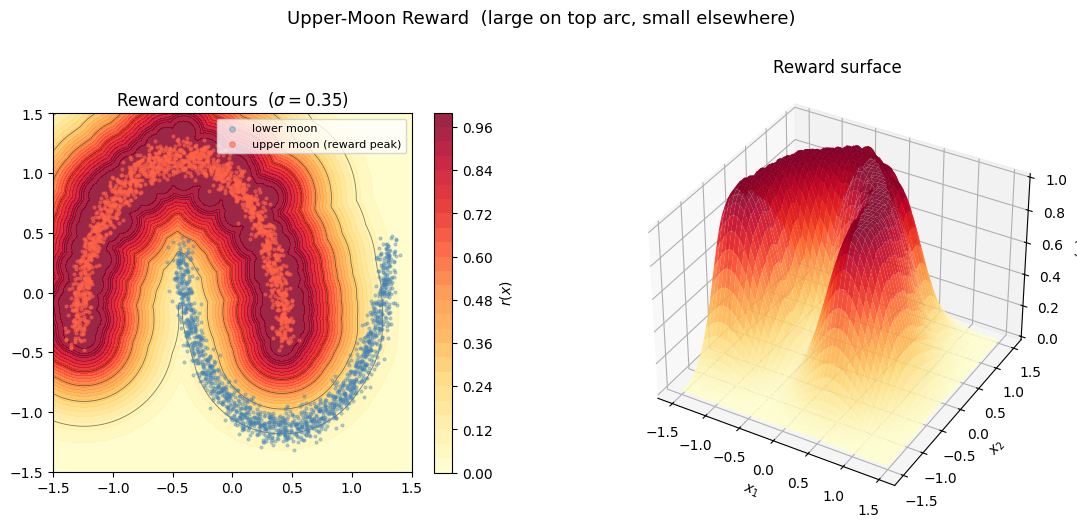

In [6]:
# ── Reward: large on the upper moon, small elsewhere ─────────────────────────
# Uses an RBF envelope over reference points on sklearn's upper moon (label 0).
# Differentiable w.r.t. x → can be passed directly to the MPC terminal reward r(x).

from visualization_utils import reward_visualization


REWARD_SIGMA = 0.35   # width of the bump (in data coordinates after centering/scaling)
N_REF        = 400    # reference points subsampled from the upper moon

# Build reference cloud using sample_two_moons (handles all normalization).
_all, _labels = sample_two_moons(50_000, return_labels=True)
upper_mask = _labels == 0
upper_pts  = torch.tensor(_all[upper_mask], dtype=torch.float32)
perm = torch.randperm(upper_pts.shape[0])[:N_REF]
UPPER_MOON_REF = upper_pts[perm]       # (N_REF, 2) — kept on CPU


def upper_moon_reward(x: torch.Tensor) -> torch.Tensor:
    """
    Terminal reward r(x): peaks at 1 on the upper moon, decays to ~0 elsewhere.

    r(x) = exp( - min_{p in upper_moon_ref} ||x - p||^2 / (2 σ^2) )

    Args:
        x: (B, 2) positions
    Returns:
        (B,) reward values in [0, 1]
    """
    ref = UPPER_MOON_REF.to(x.device, x.dtype)
    d2 = ((x[:, None, :] - ref[None, :, :]) ** 2).sum(dim=-1)   # (B, N_REF)
    return torch.exp(-d2.min(dim=1).values / (2.0 * REWARD_SIGMA ** 2))


# Alias for MPC usage:  receding_horizon_flow_control(..., r=upper_moon_reward, ...)
r = upper_moon_reward

# Terminal reward: prefer samples with large second coordinate.
# def r(x):
#     return 2.0 * x[:, 1]

# ── Contour visualisation ─────────────────────────────────────────────────────
_X_vis, _y_vis = sample_two_moons(3000, return_labels=True)

reward_visualization(
    upper_moon_reward,
    title="Upper-Moon Reward  (large on top arc, small elsewhere)",
    contour_title=f"Reward contours  ($\\sigma={REWARD_SIGMA}$)",
    scatter_groups=[
        {
            "points": _X_vis[_y_vis == 1],
            "label": "lower moon",
            "color": "steelblue",
            "alpha": 0.35,
        },
        {
            "points": _X_vis[_y_vis == 0],
            "label": "upper moon (reward peak)",
            "color": "tomato",
            "alpha": 0.55,
            "zorder": 4,
        },
    ],
    # probe_points=[
    #     ("reward at upper-moon mean", upper_pts.mean(0)),
    #     ("reward at origin", torch.zeros(2)),
    # ],
)

step    1/20  |u*| mean = 6.0189e-01  mu mean = 2.3423e-01  max h = +2.0720e+00
step    2/20  |u*| mean = 6.3535e-01  mu mean = 4.0781e-01  max h = +1.9988e+00
step    3/20  |u*| mean = 8.9371e-01  mu mean = 5.0974e-01  max h = +1.9666e+00
step    4/20  |u*| mean = 9.6518e-01  mu mean = 5.9297e-01  max h = +1.9572e+00
step    5/20  |u*| mean = 1.0294e+00  mu mean = 6.6059e-01  max h = +1.8695e+00
step    6/20  |u*| mean = 1.0734e+00  mu mean = 7.1377e-01  max h = +1.8281e+00
step    7/20  |u*| mean = 1.1361e+00  mu mean = 7.5429e-01  max h = +1.8222e+00
step    8/20  |u*| mean = 1.1449e+00  mu mean = 7.8455e-01  max h = +1.1689e+00
step    9/20  |u*| mean = 1.1881e+00  mu mean = 8.0508e-01  max h = +9.5718e-01
step   10/20  |u*| mean = 1.2635e+00  mu mean = 7.9710e-01  max h = +8.6243e-01
step   11/20  |u*| mean = 1.2307e+00  mu mean = 7.6796e-01  max h = +6.0950e-01
step   12/20  |u*| mean = 1.3369e+00  mu mean = 7.3148e-01  max h = +5.3808e-01
step   13/20  |u*| mean = 1.4528e+00  mu

/home/shervink/flow_matching/lowdim/visualization_utils.py:226: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


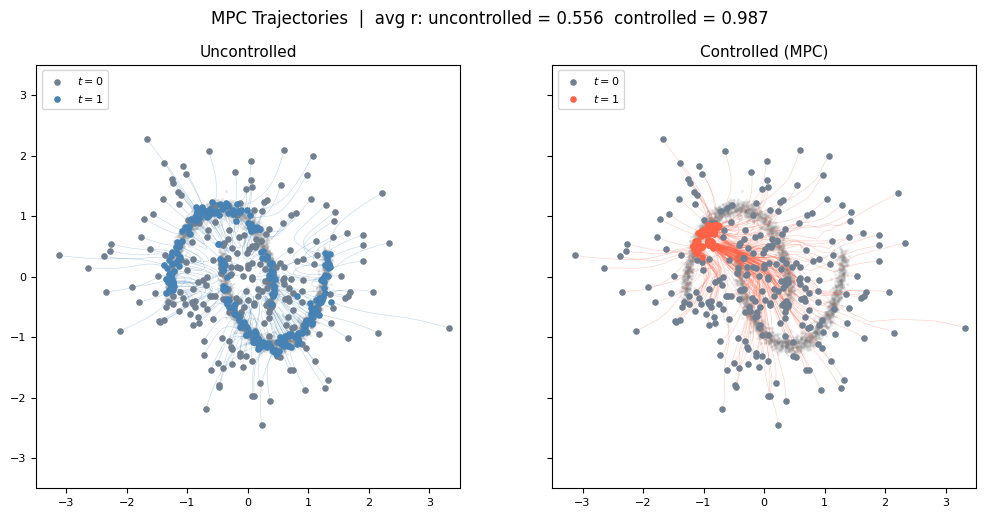

/home/shervink/flow_matching/lowdim/visualization_utils.py:258: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


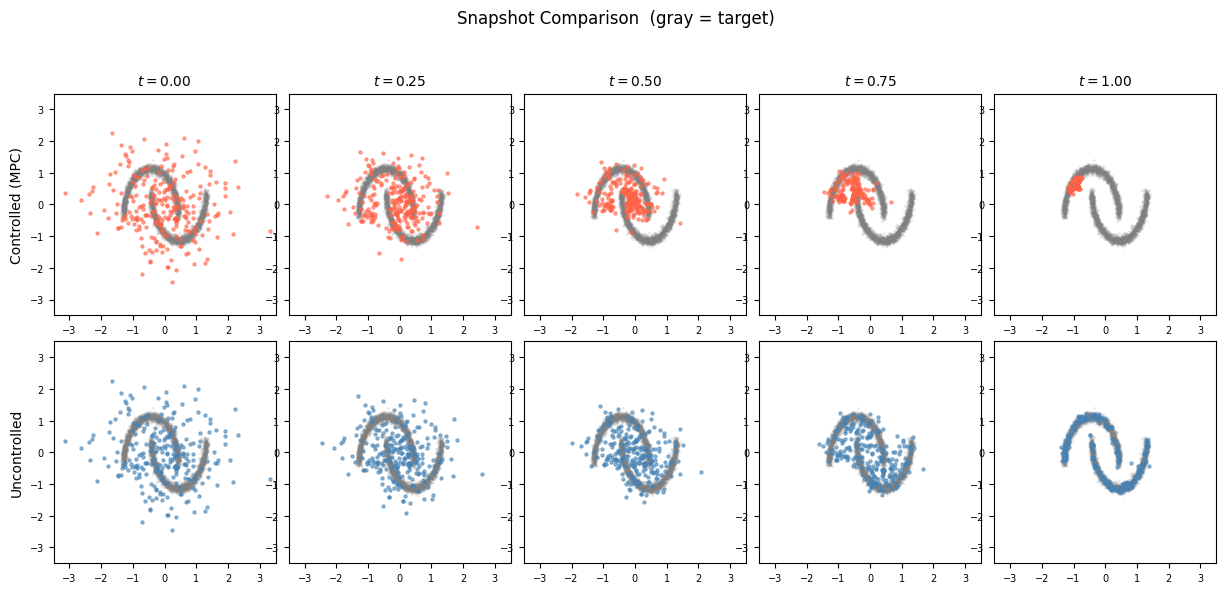

[MPC]  avg  Σ‖Δx‖²         = 0.0968   (raw integrated effort)
[MPC]  avg  Σ‖Δx‖²/(2λ)  = 0.0242   (control cost in objective, λ=2.0)


/home/shervink/flow_matching/lowdim/visualization_utils.py:301: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


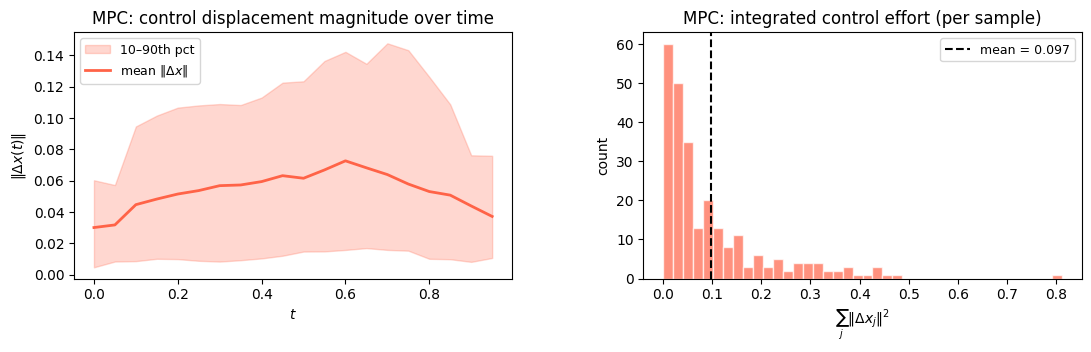

/home/shervink/flow_matching/lowdim/visualization_utils.py:361: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


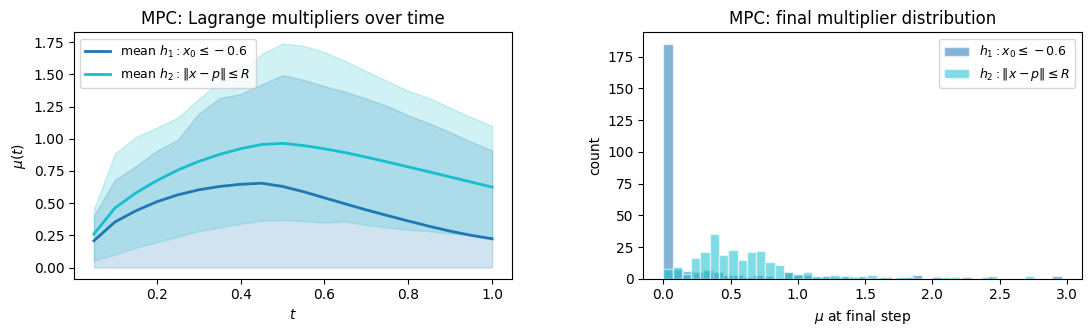

/home/shervink/flow_matching/lowdim/visualization_utils.py:407: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


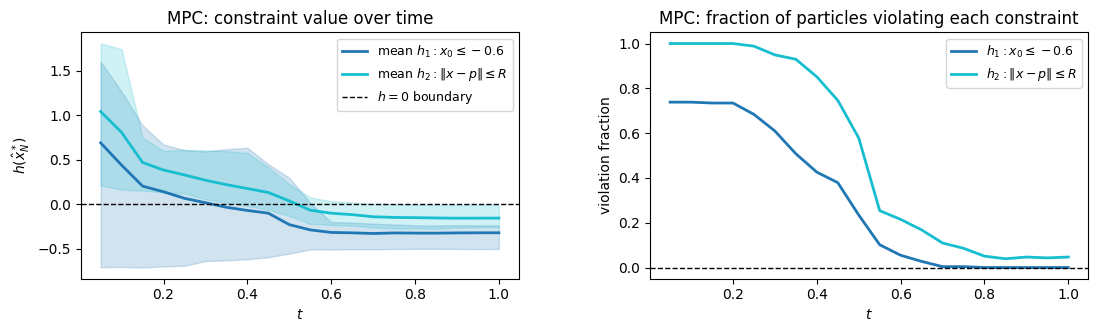

/home/shervink/flow_matching/lowdim/visualization_utils.py:459: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


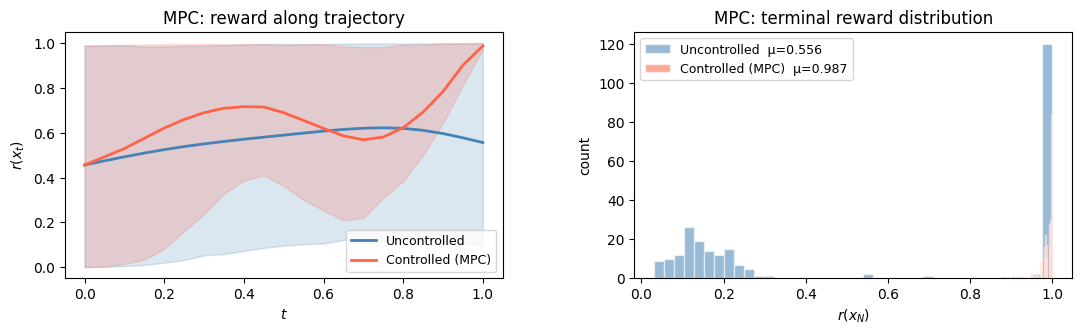

In [ ]:
import torch
from typing import Callable, Optional
import importlib
import visualization_utils
from visualization_utils import visualize_control_results
from sampling_utils import sample_target
import controllers
from controllers import receding_horizon_flow_control


# ─────────────────────────────────────────────────────────────────────────────
# Demo
# ─────────────────────────────────────────────────────────────────────────────

torch.manual_seed(0)
B, D = 256, 2
N_demo = 20
n_opt = 50

v_theta    = model.calc_b
mpc_device = next(model.parameters()).device

# Constraint reference point and radius (forbidden disk: ||x - p|| <= R)
FORBIDDEN_POINT  = torch.tensor([-0.8, 0.5])   # (2,) — moved to x.device inside h
FORBIDDEN_RADIUS = 0.35

# Inequality constraints h(x) <= 0
def h(x):
    h1 = x[:, 0] - (-0.6)   # x_0 <= -0.6
    p = FORBIDDEN_POINT.to(device=x.device, dtype=x.dtype)
    # h2 <= 0  <=>  ||x - p|| <= R  (stay inside disk centered at p)
    h2 = -FORBIDDEN_RADIUS + torch.linalg.norm(x - p, dim=-1)
    h = torch.stack([h1, h2], dim=-1)
    return h

# endpoint_map: model.forward(s, t, x) = X(s,t,x); use t=1 to predict x_N.
def endpoint_map(t_batch, x):
    ones = torch.ones_like(t_batch)
    return model(t_batch, ones, x)

x0 = torch.randn(B, D, device=mpc_device)

# Uncontrolled rollout for comparison.
dt_demo     = 1.0 / N_demo
t_grid_demo = torch.linspace(0.0, 1.0, N_demo + 1, device=mpc_device, dtype=x0.dtype)
with torch.no_grad():
    x_unc = x0.clone()
    traj_unc_list = [x_unc.clone()]
    for j in range(N_demo):
        x_unc = x_unc + dt_demo * v_theta(t_grid_demo[j], x_unc)
        traj_unc_list.append(x_unc.clone())
traj_unc = torch.stack(traj_unc_list, dim=0)  # (N+1, B, D)

xN, traj, controls, mu_final, mu_history, h_history_mpc = receding_horizon_flow_control(
    v_theta, r, x0,
    N=N_demo, H=10,
    lam=2.0,
    mu_init=0.0,
    h = h,
    constraint_on="endpoint",   # either "horizon" or "endpoint"
    endpoint_map=endpoint_map,
    lr_dual=0.25,
    optimizer="adam", n_iters=n_opt, lr=0.05,
    verbose=True, device=mpc_device,
)

print("\nfinal mean (controlled):  ", xN.mean(dim=0).tolist())
print("final mean (uncontrolled):", x_unc.mean(dim=0).tolist())
if mu_final is not None:
    print(f"mu_final  mean={mu_final.mean().item():.4f}  max={mu_final.max().item():.4f}")

# ── MPC visualisation ────────────────────────────────────────────────────────
mpc_metrics = visualize_control_results(
    traj_ctrl=traj,
    traj_unc=traj_unc,
    x0=x0,
    xN_ctrl=xN,
    xN_unc=x_unc,
    controls=controls,
    mu_history=mu_history,
    mu_labels=[r"$h_1: x_0 \leq -0.6$", r"$h_2: \|x-p\| \leq R$"],
    h_history=h_history_mpc,
    h_labels=[r"$h_1: x_0 \leq -0.6$", r"$h_2: \|x-p\| \leq R$"],
    r=r,
    show_reward_over_time=True,
    bg_pts=sample_target(4000),
    method_name="MPC",
    controlled_label="Controlled (MPC)",
    lam=2.0,
    controls_are_velocity=True,
    n_particles=256,
    show_snaps=True,
    snap_times=[0.0, 0.25, 0.5, 0.75, 1.0],
    lim=3.5,
    device=mpc_device,
)


step    1/20  t=0.050  |u| mean = 1.1578e+00  max h = -2.0928e-03  viol frac = 0.000
step    2/20  t=0.100  |u| mean = 2.1049e+00  max h = -3.0091e-02  viol frac = 0.000
step    3/20  t=0.150  |u| mean = 2.8905e+00  max h = -3.1650e-05  viol frac = 0.000
step    4/20  t=0.200  |u| mean = 3.2726e+00  max h = +2.7418e-06  viol frac = 0.113
step    5/20  t=0.250  |u| mean = 3.1756e+00  max h = +7.1526e-07  viol frac = 0.070
step    6/20  t=0.300  |u| mean = 2.9362e+00  max h = +1.3709e-06  viol frac = 0.090
step    7/20  t=0.350  |u| mean = 2.4658e+00  max h = +2.9802e-08  viol frac = 0.020
step    8/20  t=0.400  |u| mean = 1.8323e+00  max h = +5.3644e-07  viol frac = 0.043
step    9/20  t=0.450  |u| mean = 1.2475e+00  max h = +4.1127e-06  viol frac = 0.035
step   10/20  t=0.500  |u| mean = 9.2552e-01  max h = +1.6391e-06  viol frac = 0.043
step   11/20  t=0.550  |u| mean = 7.7977e-01  max h = +4.2021e-06  viol frac = 0.250
step   12/20  t=0.600  |u| mean = 7.2491e-01  max h = +3.5763e-07

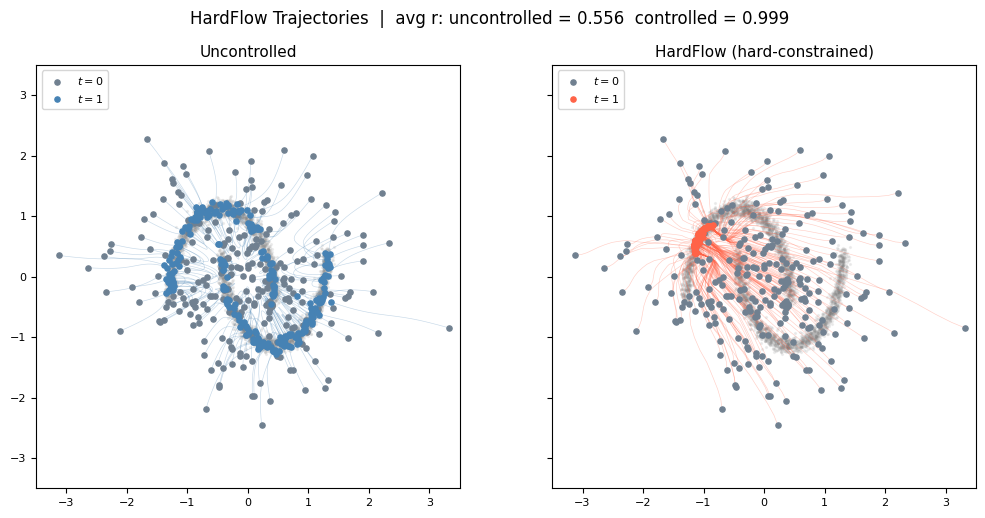

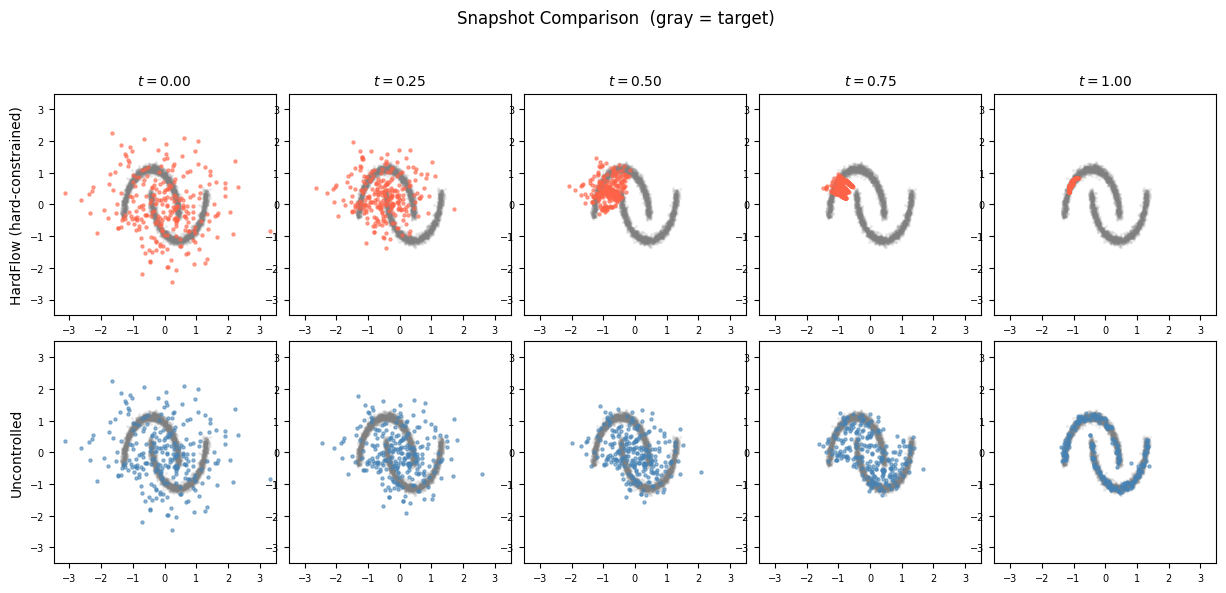

[HardFlow]  avg  Σ‖Δx‖²         = 0.1757   (raw integrated effort)
[HardFlow]  avg  Σ‖Δx‖²/(2λ)  = 0.0439   (control cost in objective, λ=2.0)


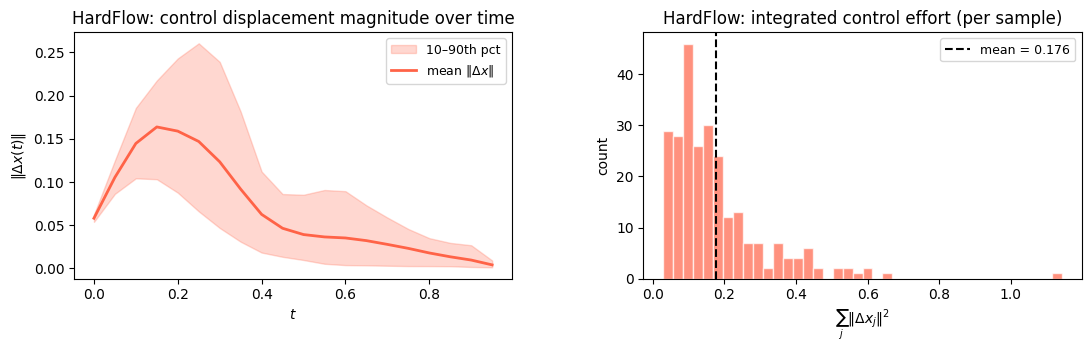

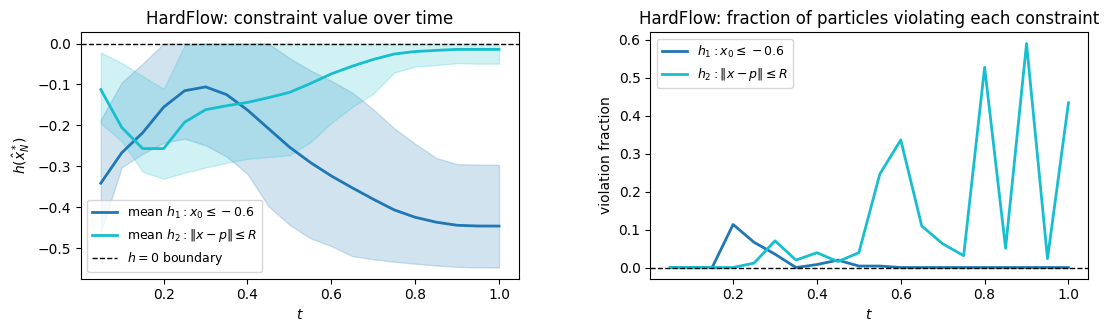

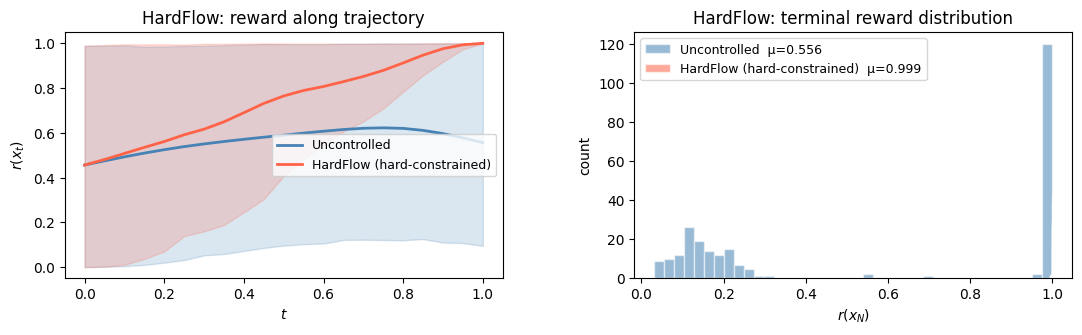

(0.5563902854919434,
 0.9991704821586609,
 0.17570677399635315,
 0.04392669349908829)

In [ ]:
"""
HardFlow demo — hard-constrained sampling on the two-moons target.

Reuses the same h(x), r(x), x0, traj_unc, x_unc, and model as the MPC cell above.

Constraints (same as MPC cell):
    h_1(x) = x_0 + 0.6  <= 0              (x_0 <= -0.6)
    h_2(x) = -R + ||x - p|| <= 0           (stay inside disk at p, radius R)
"""

import importlib
import controllers
import visualization_utils
importlib.reload(controllers)
importlib.reload(visualization_utils)
from controllers import (
    hardflow_sample,
    solve_constrained_subproblem,
    LINEAR_SCHEDULER,
)
from visualization_utils import visualize_control_results

torch.manual_seed(0)
N_hf   = 20          # discretization steps
B_hf   = x0.shape[0]

# ── Unconstrained rollout (reuse from MPC cell if shapes match, else redo) ───
dt_hf     = 1.0 / N_hf
t_grid_hf = torch.linspace(0.0, 1.0, N_hf + 1, device=mpc_device, dtype=x0.dtype)
with torch.no_grad():
    x_unc_hf = x0.clone()
    traj_unc_hf_list = [x_unc_hf.clone()]
    for j in range(N_hf):
        x_unc_hf = x_unc_hf + dt_hf * v_theta(t_grid_hf[j], x_unc_hf)
        traj_unc_hf_list.append(x_unc_hf.clone())
traj_unc_hf = torch.stack(traj_unc_hf_list, dim=0)   # (N+1, B, D)

# ── HardFlow ─────────────────────────────────────────────────────────────────
# C(x) = -r(x) so the subproblem maximises reward while enforcing h(x) <= 0.
C_cost = lambda x: -r(x)

xN_hf, traj_hf, controls_hf, h_hist_hf = hardflow_sample(
    v_theta     = v_theta,
    x0          = x0,
    h           = h,
    C           = C_cost,
    N           = N_hf,
    lam         = 0.5,
    scheduler   = LINEAR_SCHEDULER,
    t_grid      = t_grid_hf,
    solver      = solve_constrained_subproblem,
    solver_kwargs = dict(optimizer="lbfgs", n_outer=40, n_inner=8, lr=0.5, rho=10.0, rho_scale=3.0),
    warm_start  = True,
    verbose     = True,
    device      = mpc_device,
)

# ── Diagnostics ──────────────────────────────────────────────────────────────
with torch.no_grad():
    avg_r_unc_hf = r(x_unc_hf).mean().item()
    avg_r_hf     = r(xN_hf).mean().item()
    h_final      = h(xN_hf)
viol_frac = (h_final > 0).any(dim=-1).float().mean().item()
max_viol  = h_final.max().item()

print(f"\n── HardFlow results ────────────────────────────────")
print(f"avg reward  uncontrolled : {avg_r_unc_hf:.4f}")
print(f"avg reward  HardFlow     : {avg_r_hf:.4f}")
print(f"final max h              : {max_viol:+.6f}  (≤ 0 → feasible)")
print(f"violation fraction       : {viol_frac:.3f}")

# ── Visualisation (matches MPC cell exactly) ──────────────────────────────────
visualize_control_results(
    traj_ctrl             = traj_hf,
    traj_unc              = traj_unc_hf,
    x0                    = x0,
    xN_ctrl               = xN_hf,
    xN_unc                = x_unc_hf,
    controls              = controls_hf,
    h_history             = h_hist_hf,
    h_labels              = [r"$h_1: x_0 \leq -0.6$", r"$h_2: \|x-p\| \leq R$"],
    r                     = r,
    show_reward_over_time = True,
    bg_pts                = sample_target(4000),
    method_name           = "HardFlow",
    controlled_label      = "HardFlow (hard-constrained)",
    lam                   = 2.0,
    controls_are_velocity = True,
    n_particles           = 256,
    show_snaps            = True,
    snap_times            = [0.0, 0.25, 0.5, 0.75, 1.0],
    lim                   = 3.5,
    device                = mpc_device,
)

In [ ]:
import importlib
import controllers
import visualization_utils
importlib.reload(controllers)
importlib.reload(visualization_utils)
from controllers import fmrg_j
from sampling_utils import sample_two_moons, sample_target
from visualization_utils import visualize_control_results

# ── Setup ─────────────────────────────────────────────────────────────────────
N_fmrg      = 20
lim         = 3.5
fmrg_device = next(model.parameters()).device
B_fmrg      = 512
x0_fmrg     = RESCALE * torch.randn(B_fmrg, 2, device=fmrg_device)

# Uncontrolled baseline (Euler on induced velocity)
dt_fmrg     = 1.0 / N_fmrg
t_grid_fmrg = torch.linspace(0.0, 1.0, N_fmrg + 1, device=fmrg_device, dtype=x0_fmrg.dtype)
with torch.no_grad():
    x_unc_fmrg = x0_fmrg.clone()
    traj_unc_fmrg_list = [x_unc_fmrg.clone()]
    for j in range(N_fmrg):
        x_unc_fmrg = x_unc_fmrg + dt_fmrg * model.calc_b(t_grid_fmrg[j], x_unc_fmrg)
        traj_unc_fmrg_list.append(x_unc_fmrg.clone())
traj_unc_fmrg = torch.stack(traj_unc_fmrg_list, dim=0)   # (N+1, B, D)

# FMRG-J guided sampling
xN_fmrg, traj_fmrg, controls_fmrg = fmrg_j(
    model, r, x0_fmrg,
    N=N_fmrg, n_iters=3, lam=5.0,
    verbose=True, device=fmrg_device,
)

# ── Visualisation ─────────────────────────────────────────────────────────────
fmrg_metrics = visualize_control_results(
    traj_ctrl             = traj_fmrg,
    traj_unc              = traj_unc_fmrg,
    x0                    = x0_fmrg,
    xN_ctrl               = xN_fmrg,
    xN_unc                = x_unc_fmrg,
    controls              = controls_fmrg,
    r                     = r,
    show_reward_over_time = True,
    bg_pts                = sample_target(4000),
    method_name           = "FMRG-J",
    controlled_label      = "FMRG-J (guided)",
    lam                   = 2.0,
    controls_are_velocity = False,
    n_particles           = 128,
    show_snaps            = True,
    snap_times            = [0.0, 0.25, 0.5, 0.75, 1.0],
    lim                   = lim,
    device                = fmrg_device,
)

In [1]:
torch.manual_seed(0)
B, D  = 256, 2
N_sw  = 10        # steps shared by both methods in this sweep
lim   = 3.5
sweep_device = next(model.parameters()).device
v_theta_sw   = model.calc_b

x0_sw = torch.randn(B, D, device=sweep_device)

# Shared uncontrolled rollout
dt_sw     = 1.0 / N_sw
t_grid_sw = torch.linspace(0.0, 1.0, N_sw + 1, device=sweep_device, dtype=x0_sw.dtype)
with torch.no_grad():
    x_unc_sw = x0_sw.clone()
    traj_unc_sw_list = [x_unc_sw.clone()]
    for j in range(N_sw):
        x_unc_sw = x_unc_sw + dt_sw * v_theta_sw(t_grid_sw[j], x_unc_sw)
        traj_unc_sw_list.append(x_unc_sw.clone())
traj_unc_sw = torch.stack(traj_unc_sw_list, dim=0)  # (N+1, B, D)

lambs = [2.0]
rewards_mpc       = np.zeros(len(lambs))
control_costs_mpc = np.zeros(len(lambs))
rewards_fmrg      = np.zeros(len(lambs))
control_costs_fmrg = np.zeros(len(lambs))

for i, lamb in enumerate(lambs):

    # ── MPC ──────────────────────────────────────────────────────────────────
    xN, traj, controls, mu_final, mu_history, h_history_sw = receding_horizon_flow_control(
        v_theta_sw, r, x0_sw,
        N=N_sw, H=4, lam=lamb,
        optimizer="lbfgs", n_iters=30, lr=0.5,
        verbose=False, device=sweep_device,
    )
    mpc_metrics = visualize_control_results(
        traj_ctrl=traj, traj_unc=traj_unc_sw,
        x0=x0_sw, xN_ctrl=xN, xN_unc=x_unc_sw,
        controls=controls, r=r,
        bg_pts=sample_target(4000),
        method_name="MPC", controlled_label=f"MPC λ={lamb}",
        lam=lamb, controls_are_velocity=True,
        n_particles=256, show_snaps=False,
        lim=lim, device=sweep_device,
    )
    rewards_mpc[i]       = mpc_metrics[1]
    control_costs_mpc[i] = mpc_metrics[2]

    # ── FMRG-J ───────────────────────────────────────────────────────────────
    xN_fmrg, traj_fmrg, controls_fmrg = fmrg_j(
        model, r, x0_sw,
        N=N_sw, n_iters=3, lam=lamb,
        verbose=False, device=sweep_device,
    )
    fmrg_metrics = visualize_control_results(
        traj_ctrl=traj_fmrg, traj_unc=traj_unc_sw,
        x0=x0_sw, xN_ctrl=xN_fmrg, xN_unc=x_unc_sw,
        controls=controls_fmrg, r=r,
        bg_pts=sample_target(4000),
        method_name="FMRG-J", controlled_label=f"FMRG-J λ={lamb}",
        lam=lamb, controls_are_velocity=False,
        n_particles=128, show_snaps=False,
        lim=lim, device=sweep_device,
    )
    rewards_fmrg[i]       = fmrg_metrics[1]
    control_costs_fmrg[i] = fmrg_metrics[2]

    print(f"λ={lamb:5g}  MPC  r={rewards_mpc[i]:.4f} cost={control_costs_mpc[i]:.4f}"
          f"   FMRG-J r={rewards_fmrg[i]:.4f} cost={control_costs_fmrg[i]:.4f}")

plt.figure(figsize=(10, 5))
plt.scatter(control_costs_mpc,  rewards_mpc,  marker="o", label="MPC")
plt.scatter(control_costs_fmrg, rewards_fmrg, marker="x", label="FMRG-J")
plt.legend()
plt.xlabel("Control Cost")
plt.ylabel("Reward")
plt.title("Reward–Cost frontier (vary λ)")
plt.show()

NameError: name 'torch' is not defined

In [ ]:
plt.figure(figsize=(10, 5))
plt.scatter(control_costs_mpc, rewards_mpc, marker='o')
plt.scatter(control_costs_fmrg, rewards_fmrg, marker='x')
plt.xlim(-0.001, 0.125)

for x, y, lamb in zip(control_costs_mpc, rewards_mpc, lambs):
    plt.annotate(
        f"λ={lamb:g}",
        (x, y),
        textcoords="offset points",
        xytext=(4, 4),
        fontsize=7,
        color="C0",
    )

for x, y, lamb in zip(control_costs_fmrg, rewards_fmrg, lambs):
    plt.annotate(
        f"λ={lamb:g}",
        (x, y),
        textcoords="offset points",
        xytext=(4, -8),
        fontsize=7,
        color="C1",
    )


plt.legend(['MPC', 'FMRG-J'])
plt.xlabel('Control Cost')
plt.ylabel('Reward')